In [3]:
import torch

print("CUDA Available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


CUDA Available: True
GPU: NVIDIA GeForce GTX 1650 Ti


In [4]:
import os
import numpy as np
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

import torchvision.transforms as transforms
import torchvision.models as models

from sklearn.metrics import (
    confusion_matrix, classification_report, roc_curve, auc
)
from sklearn.preprocessing import label_binarize
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import seaborn as sns


In [5]:
class MRIDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        try:
            img = Image.open(self.paths[idx]).convert("RGB")
        except:
            return self.__getitem__((idx + 1) % len(self.paths))

        if self.transform:
            img = self.transform(img)

        return img, self.labels[idx]


In [6]:
root = "C:/Users/sanja/Desktop/MRI_Project/AD_DATASET/Processed_Final"
classes = ["Non_Demented", "Very_mild_Dementia", "Mild_Dementia", "Moderate_Dementia"]

image_paths = []
labels = []

for idx, cls in enumerate(classes):
    folder = os.path.join(root, cls)
    for f in os.listdir(folder):
        image_paths.append(os.path.join(folder, f))
        labels.append(idx)

labels = np.array(labels)


In [7]:
train_paths, test_paths, train_labels, test_labels = train_test_split(
    image_paths, labels, test_size=0.2, stratify=labels, random_state=42
)


In [8]:
train_transform = transforms.Compose([
    transforms.Resize((240, 240)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.4, contrast=0.4),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((240, 240)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])


In [9]:
class_counts = np.bincount(train_labels)
class_weights = 1.0 / class_counts
sample_weights = class_weights[train_labels]

sampler = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)


In [10]:
train_ds = MRIDataset(train_paths, train_labels, transform=train_transform)
test_ds  = MRIDataset(test_paths,  test_labels,  transform=test_transform)

train_loader = DataLoader(train_ds, batch_size=32, sampler=sampler,
                          num_workers=0, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False,
                         num_workers=0, pin_memory=True)


In [11]:
effnet = models.efficientnet_b1(weights=models.EfficientNet_B1_Weights.IMAGENET1K_V1)

# Freeze convolutional backbone
for param in effnet.features.parameters():
    param.requires_grad = False

# Custom classifier head
in_features = effnet.classifier[1].in_features

effnet.classifier = nn.Sequential(
    nn.Dropout(p=0.5),
    nn.Linear(in_features, 512),
    nn.ReLU(),
    nn.BatchNorm1d(512),
    nn.Dropout(0.4),
    nn.Linear(512, 4)   # your 4 classes
)

model = effnet.to(device)


In [12]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)


In [13]:
num_epochs = 20

train_loss_hist, val_loss_hist = [], []
train_acc_hist, val_acc_hist = [], []

for epoch in range(num_epochs):
    print(f"\nEpoch {epoch+1}/{num_epochs}")

    model.train()
    running_loss, correct, total = 0, 0, 0

    pbar = tqdm(train_loader, ncols=120, colour="green")

    for imgs, lbls in pbar:
        imgs, lbls = imgs.to(device), lbls.to(device)

        outputs = model(imgs)
        loss = criterion(outputs, lbls)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, preds = outputs.max(1)
        total += lbls.size(0)
        correct += preds.eq(lbls).sum().item()

        pbar.set_postfix(loss=loss.item(), acc=correct/total)

    train_loss = running_loss / len(train_loader)
    train_acc = correct / total

    # Validation
    model.eval()
    val_loss, val_correct, val_total = 0, 0, 0

    with torch.no_grad():
        for imgs, lbls in test_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            out = model(imgs)

            loss = criterion(out, lbls)
            val_loss += loss.item()

            _, preds = out.max(1)
            val_correct += preds.eq(lbls).sum().item()
            val_total += lbls.size(0)

    val_loss /= len(test_loader)
    val_acc = val_correct / val_total

    train_loss_hist.append(train_loss)
    val_loss_hist.append(val_loss)
    train_acc_hist.append(train_acc)
    val_acc_hist.append(val_acc)

    scheduler.step()

    print(f"Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")



Epoch 1/20


100%|████████████████████████████████████████████████████████| 1950/1950 [09:43<00:00,  3.34it/s, acc=0.542, loss=0.989]


Train Acc: 0.5421 | Val Acc: 0.6904

Epoch 2/20


100%|████████████████████████████████████████████████████████| 1950/1950 [09:45<00:00,  3.33it/s, acc=0.586, loss=0.944]


Train Acc: 0.5860 | Val Acc: 0.6876

Epoch 3/20


...

Train Acc: 0.6512 | Val Acc: 0.7504

Epoch 19/20


100%|████████████████████████████████████████████████████████| 1950/1950 [08:55<00:00,  3.64it/s, acc=0.654, loss=0.883]


Train Acc: 0.6543 | Val Acc: 0.7658

Epoch 20/20


100%|█████████████████████████████████████████████████████████| 1950/1950 [08:54<00:00,  3.65it/s, acc=0.656, loss=1.12]


Train Acc: 0.6557 | Val Acc: 0.7519


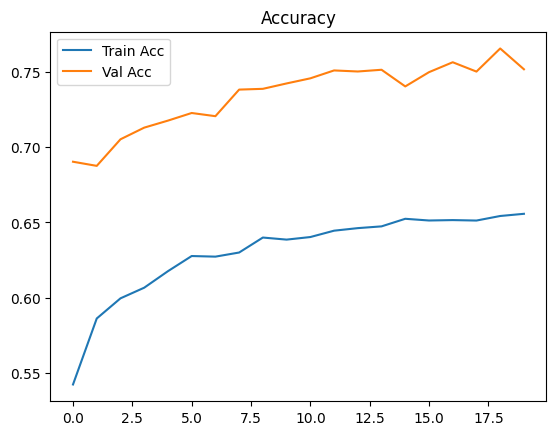

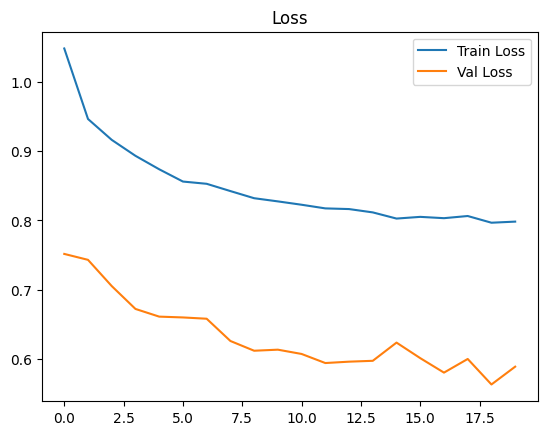

In [14]:
plt.plot(train_acc_hist); plt.plot(val_acc_hist)
plt.legend(["Train Acc","Val Acc"]); plt.title("Accuracy"); plt.show()

plt.plot(train_loss_hist); plt.plot(val_loss_hist)
plt.legend(["Train Loss","Val Loss"]); plt.title("Loss"); plt.show()


In [15]:
model.eval()
all_probs, all_preds, all_labels = [], [], []

with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs = imgs.to(device)
        out = model(imgs)

        probs = torch.softmax(out, dim=1).cpu().numpy()
        preds = np.argmax(probs, axis=1)

        all_probs.extend(probs)
        all_preds.extend(preds)
        all_labels.extend(lbls.numpy())


In [16]:
print(classification_report(all_labels, all_preds, target_names=classes))


                    precision    recall  f1-score   support

      Non_Demented       0.89      0.85      0.87      8000
Very_mild_Dementia       0.67      0.52      0.58      4000
     Mild_Dementia       0.51      0.68      0.58      2000
 Moderate_Dementia       0.67      0.94      0.78      1600

          accuracy                           0.75     15600
         macro avg       0.69      0.75      0.71     15600
      weighted avg       0.76      0.75      0.75     15600



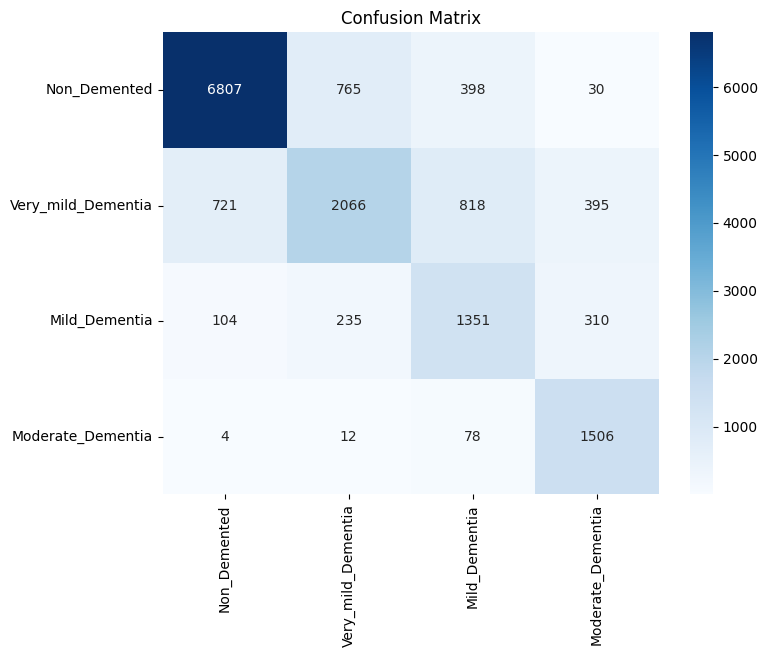

In [17]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix")
plt.show()


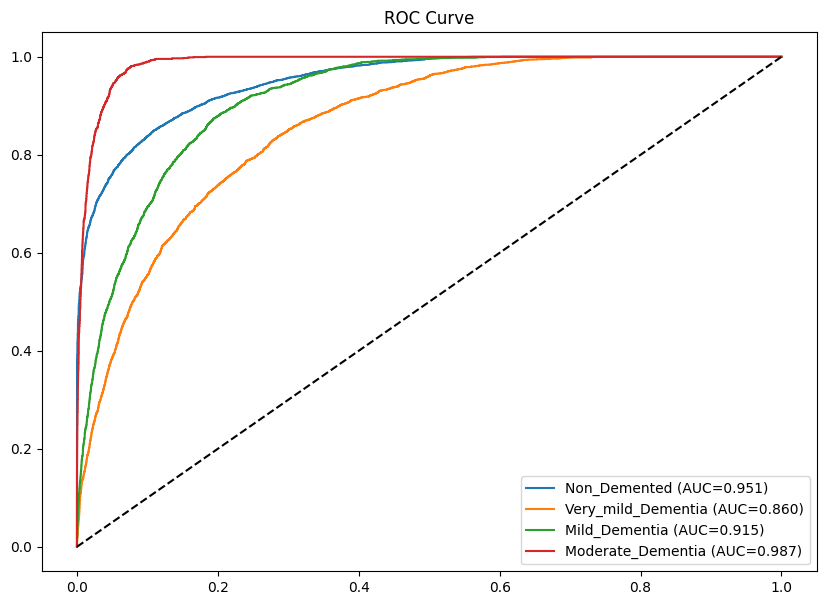

In [18]:
y_bin = label_binarize(all_labels, classes=[0,1,2,3])
all_probs = np.array(all_probs)

plt.figure(figsize=(10,7))

for i in range(4):
    fpr, tpr, _ = roc_curve(y_bin[:,i], all_probs[:,i])
    score = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{classes[i]} (AUC={score:.3f})")

plt.plot([0,1],[0,1],'k--')
plt.title("ROC Curve")
plt.legend()
plt.show()
